In [7]:
%load_ext autoreload
%autoreload 2


import scanpy as sc
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import scvi
from dotenv import load_dotenv; load_dotenv()
import os
import glob
import pandas as pd

from utils import preprocessing

# Hyperparamyters
BASE_PATH = os.getenv("BASE_PATH_FOR_SAVING")
print(f"BASE_PATH: {BASE_PATH}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
BASE_PATH: /home/gdallagl/myworkdir/data/XDP


# Find and Load all Libraries (H+D)

In [8]:
adatas = []

for i, path in enumerate(sorted(glob.glob(f"{BASE_PATH}/SlideTags_dataset/SlideTags_single_libraries/*/*/*/adata/doublets_filtered_adata.h5ad"))):
    
    # Parse metadata from path: BASE/disease_type/sample_id/BCL/library/adata/file
    parts = path.replace(BASE_PATH + "/", "").split("/")
    sample_id, bcl, library = parts[2], parts[3], parts[4]
    
    print(f"Loading: {sample_id}/{library} : {i+1}th library")

    #continue

    adata = sc.read_h5ad(path)
    #display(adata)

    ###Create minimal adata

    # 1. fitler same obs
    adata.obs = adata.obs[['x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', "sample",
                           
                           'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 
                           'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 
                           'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability',
                           'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability',
                           'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability',

                           'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 
                           
                           ]]

    # 2. same infos
    adata.var    = adata.var[['feature_types', 'genome', 'gene_symbol']]
    adata.obsm   = {k: adata.obsm[k].copy()   for k in ('spatial',) if k in adata.obsm}
    adata.layers = {k: adata.layers[k].copy() for k in ('counts',)  if k in adata.layers}
    
    # Add per-library metadata
    assert adata.obs["sample"].unique()[0] == sample_id # needed for join 
    adata.obs["library_id"] = bcl + "_" + library

    # save original barcode before making obs_names unique
    adata.obs["original_barcode"] = adata.obs_names.astype(str)

    # make cell index unique
    adata.obs_names = bcl + "---" + library + "---" + adata.obs_names.astype(str)

    # restart from raw counts
    adata.X = adata.layers["counts"].copy()
    
    adatas.append(adata)

print(f"\nLoaded {len(adatas)} libraries")


Loading: sample_01/SI-TT-H1 : 1th library
Loading: sample_01/SI-TT-H2 : 2th library
Loading: sample_01/SI-TT-H3 : 3th library
Loading: sample_02/SI-TT-B10 : 4th library
Loading: sample_02/SI-TT-B11 : 5th library
Loading: sample_02/SI-TT-B12 : 6th library
Loading: sample_02/SI-TT-C1 : 7th library
Loading: sample_03/SI-TT-C2 : 8th library
Loading: sample_03/SI-TT-C3 : 9th library
Loading: sample_03/SI-TT-C4 : 10th library
Loading: sample_03/SI-TT-C5 : 11th library
Loading: sample_04/SI-TT-C6 : 12th library
Loading: sample_04/SI-TT-C7 : 13th library
Loading: sample_04/SI-TT-C8 : 14th library
Loading: sample_04/SI-TT-C9 : 15th library
Loading: sample_05/SI-TT-D7 : 16th library
Loading: sample_05/SI-TT-D8 : 17th library
Loading: sample_05/SI-TT-D9 : 18th library
Loading: sample_06/SI-TT-E7 : 19th library
Loading: sample_06/SI-TT-E8 : 20th library
Loading: sample_06/SI-TT-E9 : 21th library
Loading: sample_07/SI-TT-E10 : 22th library
Loading: sample_07/SI-TT-E11 : 23th library
Loading: sample

# Check gene overlap

they soudl eb ll the same:
- no gene remvoel before this point
- used same ref in cellrnager

In [9]:
gene_sets = [set(a.var_names) for a in adatas]
inner = gene_sets[0].intersection(*gene_sets[1:])
outer = gene_sets[0].union(*gene_sets[1:])

print(f"N libraries:           {len(adatas)}")
print(f"INNER join (common):   {len(inner):,} genes")
print(f"OUTER join (union):    {len(outer):,} genes")
print(f"Genes lost vs outer:   {len(outer) - len(inner):,}")
print()
for i, (a, gs) in enumerate(zip(adatas, gene_sets)):
    sample = a.obs['sample'].iloc[0]
    print(f"  lib {i+1} ({sample}): {len(gs):,} genes  |  unique to this lib: {len(gs - inner):,}")


N libraries:           51
INNER join (common):   38,606 genes
OUTER join (union):    38,606 genes
Genes lost vs outer:   0

  lib 1 (sample_01): 38,606 genes  |  unique to this lib: 0
  lib 2 (sample_01): 38,606 genes  |  unique to this lib: 0
  lib 3 (sample_01): 38,606 genes  |  unique to this lib: 0
  lib 4 (sample_02): 38,606 genes  |  unique to this lib: 0
  lib 5 (sample_02): 38,606 genes  |  unique to this lib: 0
  lib 6 (sample_02): 38,606 genes  |  unique to this lib: 0
  lib 7 (sample_02): 38,606 genes  |  unique to this lib: 0
  lib 8 (sample_03): 38,606 genes  |  unique to this lib: 0
  lib 9 (sample_03): 38,606 genes  |  unique to this lib: 0
  lib 10 (sample_03): 38,606 genes  |  unique to this lib: 0
  lib 11 (sample_03): 38,606 genes  |  unique to this lib: 0
  lib 12 (sample_04): 38,606 genes  |  unique to this lib: 0
  lib 13 (sample_04): 38,606 genes  |  unique to this lib: 0
  lib 14 (sample_04): 38,606 genes  |  unique to this lib: 0
  lib 15 (sample_04): 38,606 ge

# Concatenate

**ATTENTION**: how to join genes

In [10]:
# Save var info from FISRT dataset before concat

JOIN_GENE_MODALITY = "inner"

# # FOR INNER JOIN
if JOIN_GENE_MODALITY == "inner":
    var_info = adatas[0].var[['feature_types', 'genome', 'gene_symbol']].copy()

# FOR OUTER JOIN
if JOIN_GENE_MODALITY == "outer":
    var_info = pd.concat([
        a.var[['feature_types', 'genome', 'gene_symbol']]
        for a in adatas
    ]).groupby(level=0).first()  # deduplicate gene entries, keep first occurrence

# Concate
adata = sc.concat(adatas, 
                  
                # Not aligned to the concatenation axis (i.e., things in .uns, .var, .varm, .obsm, etc.) are selected/combined
                  
                # No need as we make barcodes ouqnie before
                #   index_unique='-',
                #   keys=LIBRARIES, # add to the obs_name the library name as prefix, separated by "index unique"

                join=JOIN_GENE_MODALITY
)  # keeps COMMON genes
del adatas

# Restore var info for common genes
adata.var = var_info.loc[adata.var_names]

# ATTENTION : now same genes coild be no more expressed
sc.pp.filter_genes(adata, min_cells=3)

print(adata)
display(adata.obs.head(3))
display(adata.var.head(3))
assert adata.obs_names.is_unique, "ERROR: adata.obs_names are not unique!"
assert adata.var_names.is_unique, "ERROR: adata.var_names are not unique!"



AnnData object with n_obs × n_vars = 742896 × 37588
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'original_barcode'
    var: 'feature_types', 'genome', 'gene_symbol', 'n_cells'
    obsm: 'spatial'
    layers: 'counts'


,x,y,pct_intronic,dbscan_clusters,dbscan_score,has_spatial,sample,Neighborhood_name,Neighborhood_bootstrapping_probability,Neighborhood_aggregate_probability,...,Cluster_bootstrapping_probability,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,library_id,original_barcode
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGATAACAG-1,33013.428400,444.562211,0.585746,3.0,0.230731,False,sample_01,Nonneuron,1.0,1.0,...,1.00,3675,8.209580,7489,8.921324,21,3.091042,0.280411,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,AAACCAAAGATAACAG-1
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGCATGGAG-1,21225.159553,4193.340108,0.596834,1.0,0.942997,True,sample_01,Nonneuron,1.0,1.0,...,0.41,2180,7.687539,4352,8.378621,3,1.386294,0.068934,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,AAACCAAAGCATGGAG-1
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGCGGAGT-1,16429.015488,3852.143369,0.716821,1.0,0.936590,True,sample_01,Nonneuron,1.0,1.0,...,1.00,2406,7.786136,6496,8.779096,0,0.000000,0.000000,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,AAACCAAAGGCGGAGT-1


,feature_types,genome,gene_symbol,n_cells
ensembl_id,,,,
ENSG00000290825,Gene Expression,GRCh38,DDX11L2,171
ENSG00000243485,Gene Expression,GRCh38,MIR1302-2HG,766
ENSG00000237613,Gene Expression,GRCh38,FAM138A,3


# Add Metadata

In [11]:
df_meta = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/SlideTags_XDP_metadata/XDP Slidetags - CellBender Terra table - cb.csv")
display(df_meta.columns)

df_meta = df_meta[[
        "entity:library_id", "donor_number", "donor_id", 
        "condition", "sex", "repeat_length", "age_at_onset", "age_at_death", "bcl", "RNAindex", "Sorted", "Batch"]]
df_meta.rename(columns={"entity:library_id": "library_id", "RNAindex": "library"}, inplace=True)
df_meta

Index(['entity:library_id', 'donor_number', 'donor_id', 'Batch', 'condition',
       'sex', 'repeat_length', 'age_at_onset', 'age_at_death', 'bcl',
       'original_bcl', 'RNAindex', 'SBindex', 'Sorted', 'puck_paths', 'Puck',
       'reference', 'cellranger_count_h5', 'fastq_folder_path',
       'bam_folder_path', 'cellbender_output_dir', 'cellbender_fpr',
       'chemistry_used', 'Notes'],
      dtype='object')

,library_id,donor_number,donor_id,condition,sex,repeat_length,age_at_onset,age_at_death,bcl,library,Sorted,Batch
0,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,sample_01,SCF-18-003,diseased,male,42,32,41,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H1,Unsorted,1
1,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H2,sample_01,SCF-18-003,diseased,male,42,32,41,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H2,Unsorted,1
2,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H3,sample_01,SCF-18-003,diseased,male,42,32,41,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H3,NeUN+,1
3,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B10,sample_02,SCF-20-025,diseased,male,38,51,58,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-B10,Unsorted,2
4,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B11,sample_02,SCF-20-025,diseased,male,38,51,58,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-B11,Unsorted,2
5,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B12,sample_02,SCF-20-025,diseased,male,38,51,58,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-B12,Unsorted,2
6,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C1,sample_02,SCF-20-025,diseased,male,38,51,58,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-C1,NeUN+,2
7,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C2,sample_03,SCF-19-014,diseased,male,50,30,32,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-C2,Unsorted,2
8,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C3,sample_03,SCF-19-014,diseased,male,50,30,32,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-C3,Unsorted,2
9,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C4,sample_03,SCF-19-014,diseased,male,50,30,32,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-C4,Unsorted,2


In [12]:
#lets check before
adata.obs.merge(df_meta, left_on="library_id", right_on="library_id", how="left")

,x,y,pct_intronic,dbscan_clusters,dbscan_score,has_spatial,sample,Neighborhood_name,Neighborhood_bootstrapping_probability,Neighborhood_aggregate_probability,...,donor_id,condition,sex,repeat_length,age_at_onset,age_at_death,bcl,library,Sorted,Batch
0,33013.428400,444.562211,0.585746,3.0,0.230731,False,sample_01,Nonneuron,1.00,1.00,...,SCF-18-003,diseased,male,42,32,41,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H1,Unsorted,1
1,21225.159553,4193.340108,0.596834,1.0,0.942997,True,sample_01,Nonneuron,1.00,1.00,...,SCF-18-003,diseased,male,42,32,41,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H1,Unsorted,1
2,16429.015488,3852.143369,0.716821,1.0,0.936590,True,sample_01,Nonneuron,1.00,1.00,...,SCF-18-003,diseased,male,42,32,41,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H1,Unsorted,1
3,43242.438818,-1822.457007,0.609493,0.0,0.366933,False,sample_01,Nonneuron,1.00,1.00,...,SCF-18-003,diseased,male,42,32,41,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H1,Unsorted,1
4,14118.369028,-4852.270550,0.588186,1.0,0.859807,True,sample_01,Nonneuron,1.00,1.00,...,SCF-18-003,diseased,male,42,32,41,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H1,Unsorted,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
742891,35002.539607,-2215.668368,0.759874,1.0,0.996100,True,sample_12,Subpallium GABA,0.68,0.68,...,SCF-22-065,healthy,male,not_applicable,not_applicable,69,260721_SL-EXB_0892_B23Y3GKLT4,SI-TT-H3,NeUN+,6
742892,9228.794116,1053.109411,0.774319,1.0,0.995154,True,sample_12,Subpallium GABA,1.00,1.00,...,SCF-22-065,healthy,male,not_applicable,not_applicable,69,260721_SL-EXB_0892_B23Y3GKLT4,SI-TT-H3,NeUN+,6
742893,26039.976024,141.914384,0.756758,1.0,0.958534,True,sample_12,Subpallium GABA,1.00,1.00,...,SCF-22-065,healthy,male,not_applicable,not_applicable,69,260721_SL-EXB_0892_B23Y3GKLT4,SI-TT-H3,NeUN+,6
742894,47745.124273,-9436.079408,0.743346,7.0,0.290273,False,sample_12,Subpallium GABA,1.00,1.00,...,SCF-22-065,healthy,male,not_applicable,not_applicable,69,260721_SL-EXB_0892_B23Y3GKLT4,SI-TT-H3,NeUN+,6


In [13]:
obs_index = adata.obs.index
adata.obs = adata.obs.merge(df_meta, on="library_id", how="left")
adata.obs.index = obs_index

adata.obs.columns

/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Index(['x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score',
       'has_spatial', 'sample', 'Neighborhood_name',
       'Neighborhood_bootstrapping_probability',
       'Neighborhood_aggregate_probability', 'Class_name',
       'Class_bootstrapping_probability', 'Class_aggregate_probability',
       'Subclass_name', 'Subclass_bootstrapping_probability',
       'Subclass_aggregate_probability', 'Group_name',
       'Group_bootstrapping_probability', 'Group_aggregate_probability',
       'Cluster_label', 'Cluster_name', 'Cluster_alias',
       'Cluster_bootstrapping_probability', 'n_genes_by_counts',
       'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts',
       'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt',
       'library_id', 'original_barcode', 'donor_number', 'donor_id',
       'condition', 'sex', 'repeat_length', 'age_at_onset', 'age_at_death',
       'bcl', 'library', 'Sorted', 'Batch'],
      dtype='object')

In [14]:
# check for nan
for col in adata.obs.columns:
    print(col)
    if adata.obs[col].isnull().any():
        print(f"Column '{col}' has NaN values.")
    print(adata.obs[col].nunique())
    print()
    #break

x
Column 'x' has NaN values.
620392

y
Column 'y' has NaN values.
620392

pct_intronic
697492

dbscan_clusters
Column 'dbscan_clusters' has NaN values.
176

dbscan_score
Column 'dbscan_score' has NaN values.
455588

has_spatial
2

sample
12

Neighborhood_name
4

Neighborhood_bootstrapping_probability
55

Neighborhood_aggregate_probability
55

Class_name
12

Class_bootstrapping_probability
51

Class_aggregate_probability
1077

Subclass_name
36

Subclass_bootstrapping_probability
73

Subclass_aggregate_probability
3435

Group_name
59

Group_bootstrapping_probability
69

Group_aggregate_probability
5241

Cluster_label
424

Cluster_name
424

Cluster_alias
424

Cluster_bootstrapping_probability
85

n_genes_by_counts
14042

log1p_n_genes_by_counts
14042

total_counts
86209

log1p_total_counts
86209

total_counts_mt
2401

log1p_total_counts_mt
2401

pct_counts_mt
384262

library_id
51

original_barcode
661287

donor_number
12

donor_id
12

condition
2

sex
1

repeat_length
9

age_at_onset
7



# Save

In [15]:
SAVE_PATH = f"{BASE_PATH}/SlideTags_dataset/all_lib_adata.h5ad"
print(f"Saving merged adata to: {SAVE_PATH}")


Saving merged adata to: /home/gdallagl/myworkdir/data/XDP/SlideTags_dataset/all_lib_adata.h5ad


In [16]:
adata.write(SAVE_PATH)
adata

AnnData object with n_obs × n_vars = 742896 × 37588
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'original_barcode', 'donor_number', 'donor_id', 'condition', 'sex', 'repeat_length', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'Batch'
    var: 'feature_types', 'genome', 'gene_symbol', 'n_cells'
    obsm: 'spatial'
    layers: 'counts'

In [17]:
adata = sc.read_h5ad(SAVE_PATH)
adata   

AnnData object with n_obs × n_vars = 742896 × 37588
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'original_barcode', 'donor_number', 'donor_id', 'condition', 'sex', 'repeat_length', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'Batch'
    var: 'feature_types', 'genome', 'gene_symbol', 'n_cells'
    obsm: 'spatial'
    layers: 'counts'

# Plots

Sample: sample_01


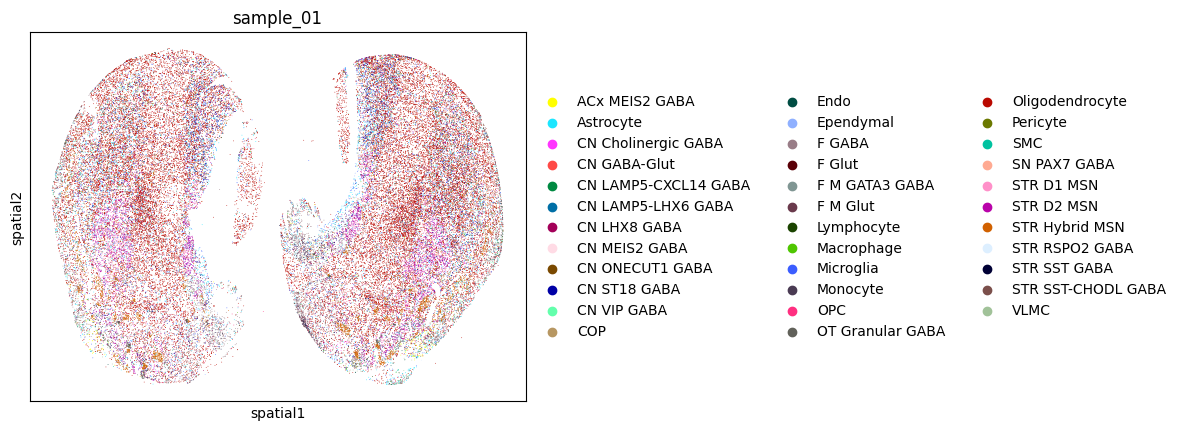

Sample: sample_02


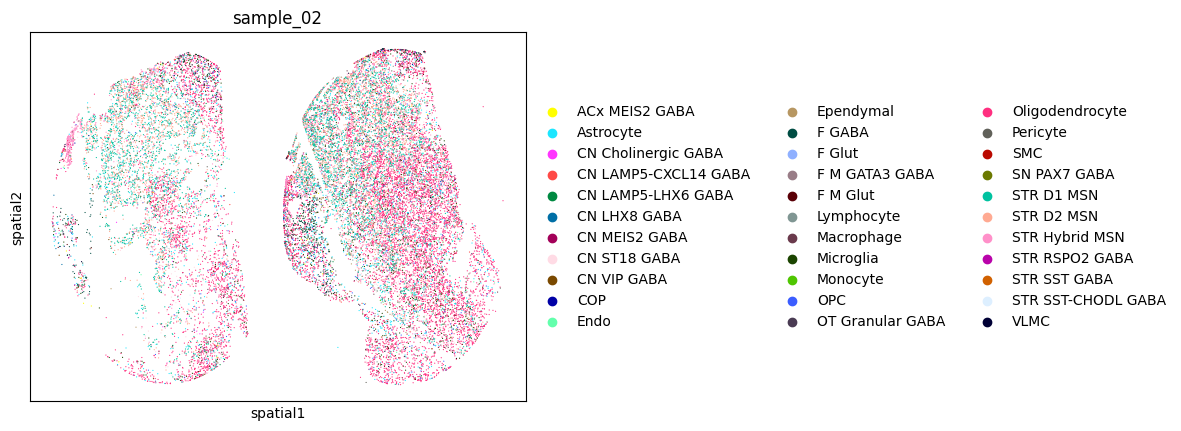

Sample: sample_03


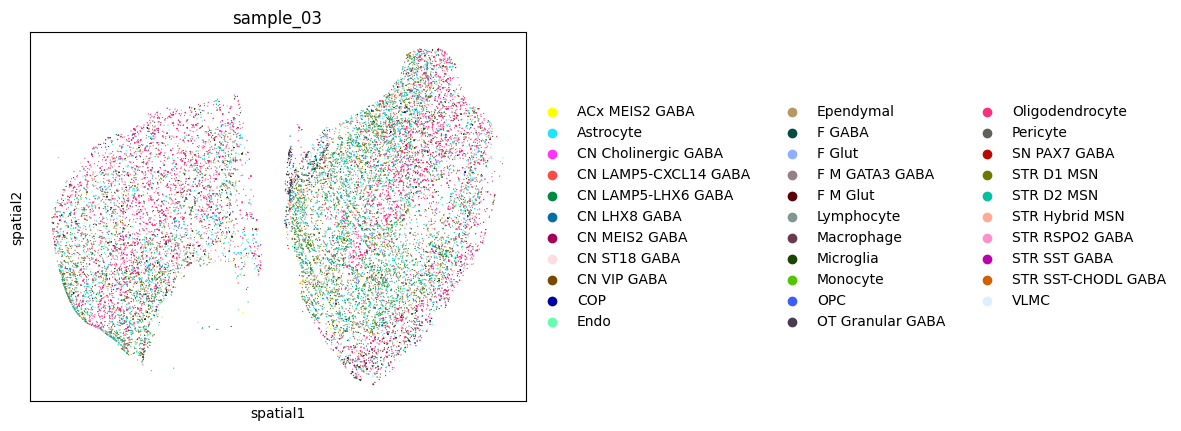

Sample: sample_04


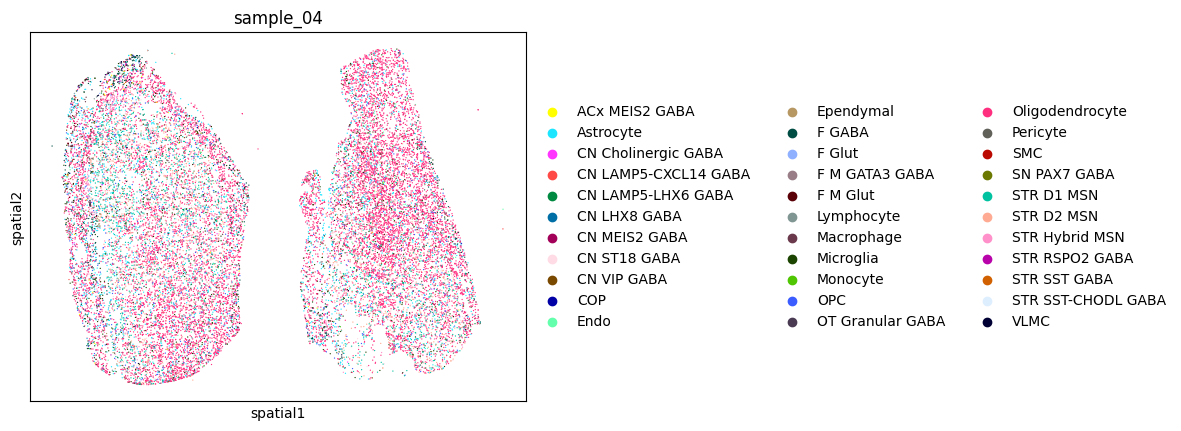

Sample: sample_05


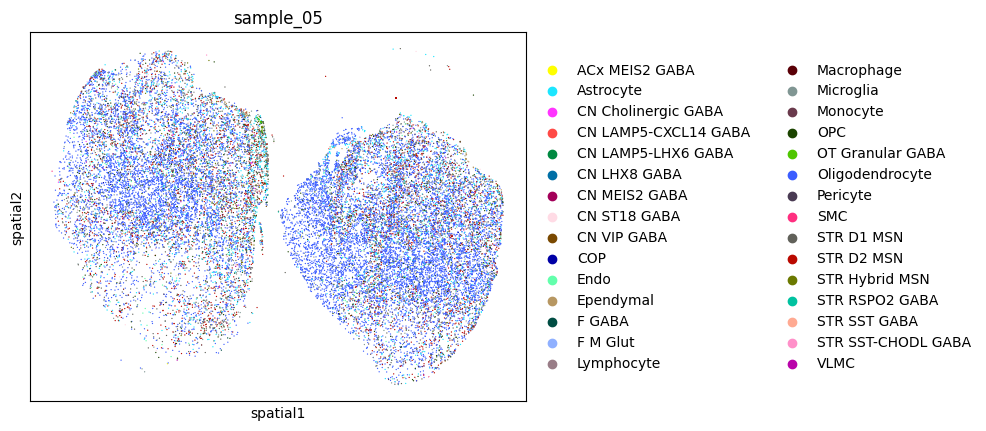

Sample: sample_06


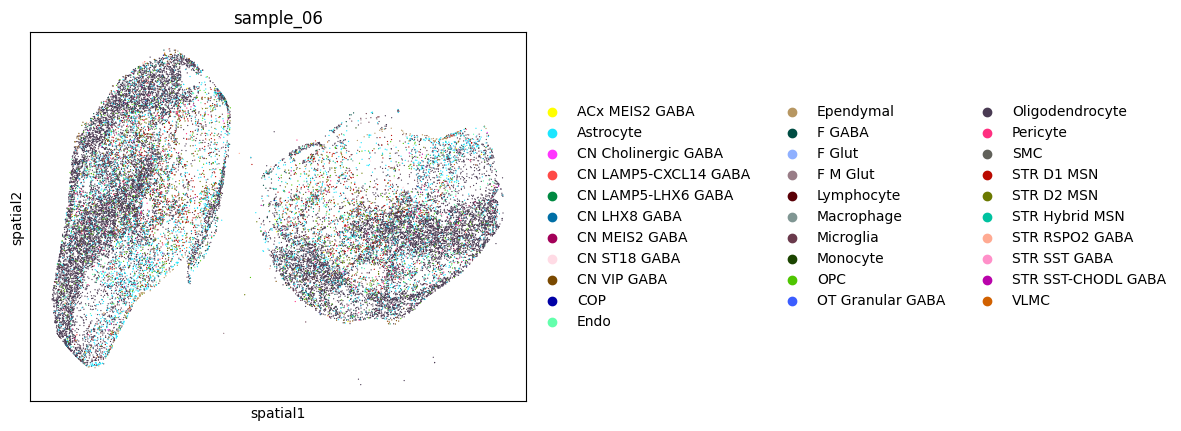

Sample: sample_07


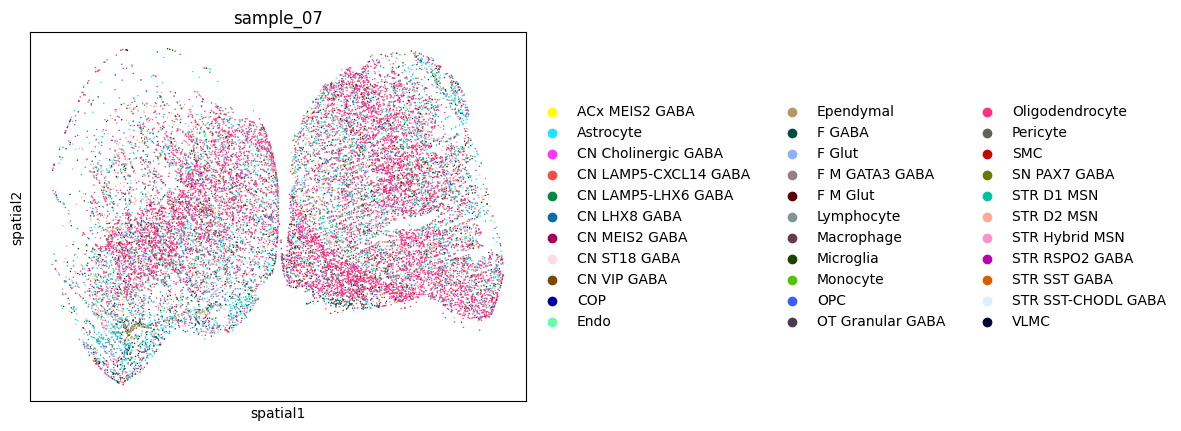

Sample: sample_08


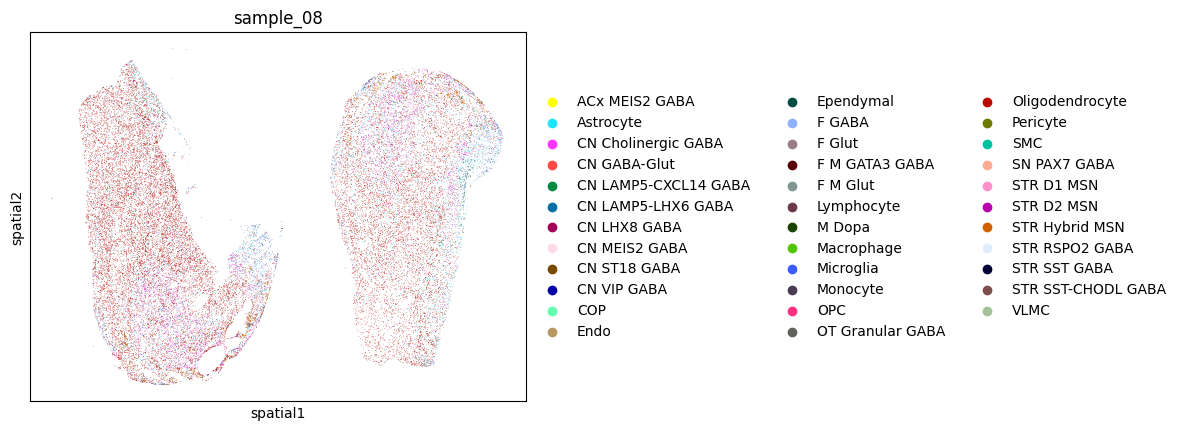

Sample: sample_09


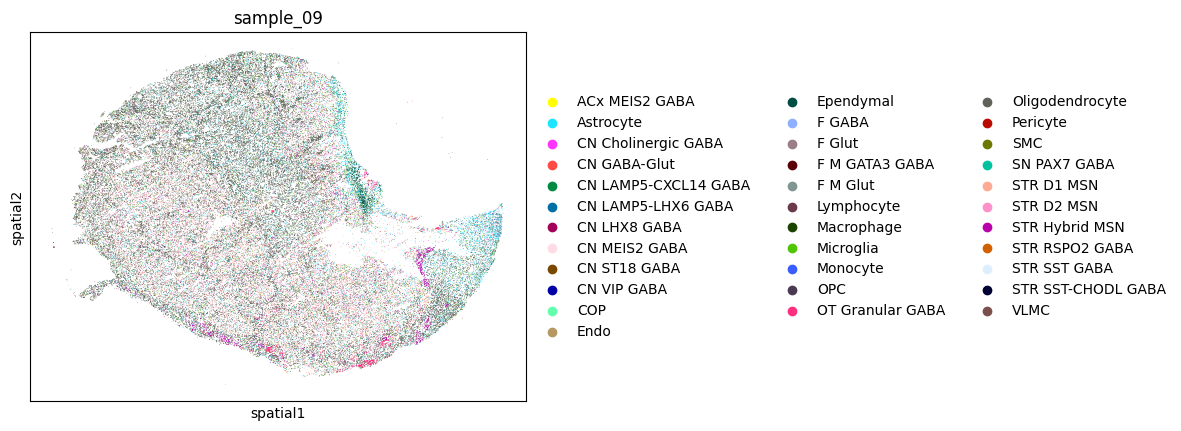

Sample: sample_10


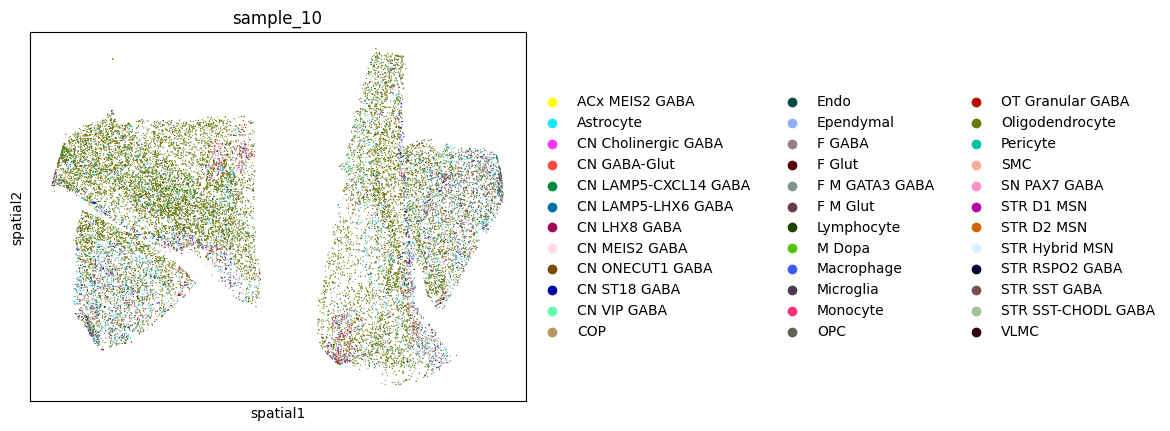

Sample: sample_11


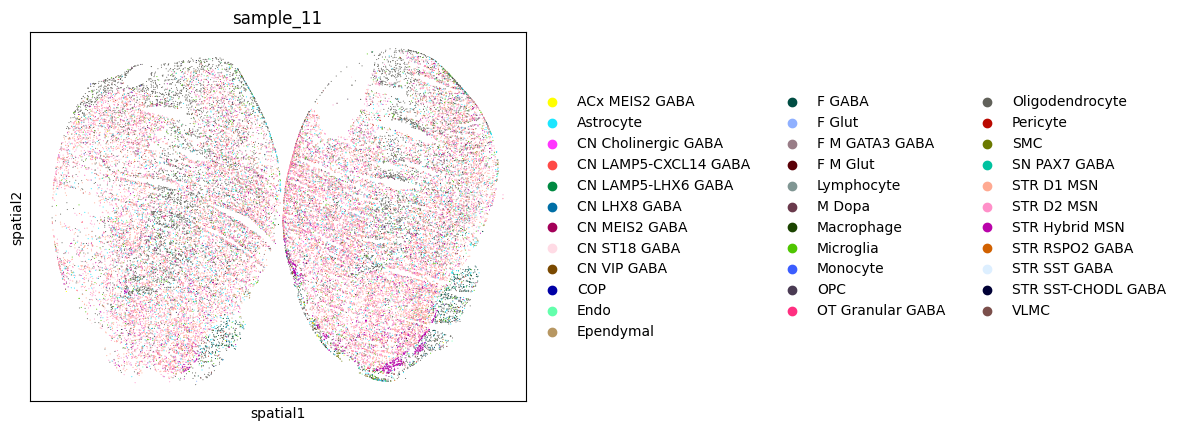

Sample: sample_12


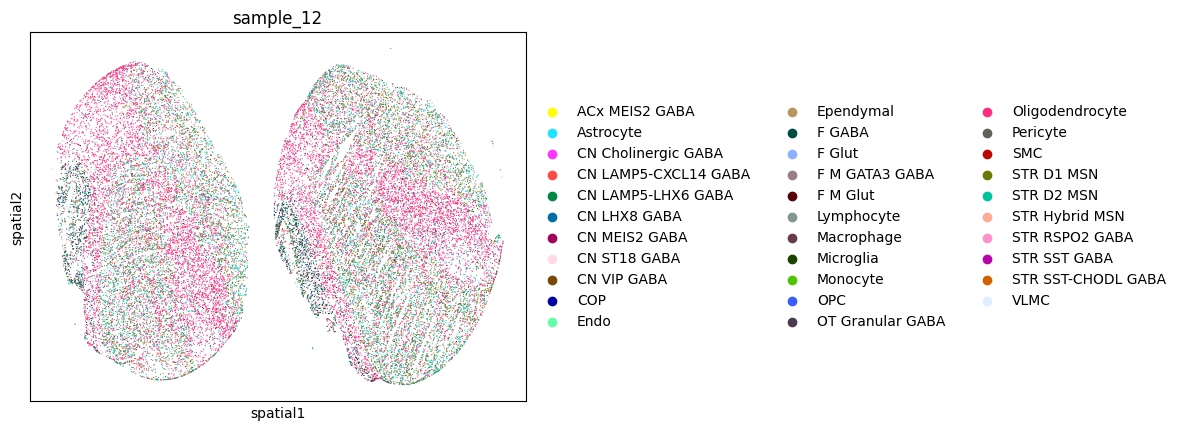

In [18]:
for s in adata.obs['sample'].unique():
    print(f"Sample: {s}")
    sc.pl.embedding(adata[adata.obs['sample'] == s].copy(), basis="spatial", color="Subclass_name", title=s)
    plt.show()

# ---
# ---
# ---